<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/notebooks/notebooks/03_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Loading in CLean data

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

path = '/content/drive/MyDrive/Datasets/'
train = pd.read_csv(path + 'train_clean.csv')
test  = pd.read_csv(path + 'test_clean.csv')
print(train.shape, test.shape)

Mounted at /content/drive
(107740, 43) (82332, 43)


In [ ]:
#Skill ut X somer features og Y somer fasit

X_train = train.drop(columns=['label', 'attack_cat'])
y_train = train['label']
X_test  = test.drop(columns=['label', 'attack_cat'])
y_test  = test['label']

#Hvorfor: modellen skal lære å gjette svaret, så svaret kan ikke ligge blant features.
#attack_cat må også ut av X: den avslører svaret direkte, fordi alt som ikke er “Normal” er et angrep.


In [ ]:
#Del train i trening og validering

from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

#Hvorfor: vi skal ta mange valg (modell, innstillinger, features).
#Valgene tas ut fra valideringssettet. Testsettet røres ikke før helt til slutt,
#ellers tilpasser vi oss testsettet og får for gode resultater.

#stratify=y_train gir lik andel angrep og normal i begge delene.
#random_state=42 gjør at alle får samme oppdeling.

In [ ]:
#Del kolonnene i grupper

cat_cols = ['proto', 'service', 'state']
num_cols = X_tr.columns.drop(cat_cols).tolist()

skew = X_tr[num_cols].skew()
skew_cols  = skew[skew.abs() > 1].index.tolist()
other_cols = [c for c in num_cols if c not in skew_cols]

print(len(cat_cols), len(skew_cols), len(other_cols))

#Hvorfor: de tre typene kolonner trenger ulik behandling:
# -Kategoriske (tekst) må gjøres om til tall.
# -Skjeve tallkolonner trenger log-transformasjon før skalering.
# -Øvrige tallkolonner trenger bare skalering.

#Skjevheten beregnes bare på X_tr, altså treningsdelen.

3 32 6


In [ ]:
# Bygg preprossesering

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

preprocess = ColumnTransformer([
    ('cat',  OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('skew', Pipeline([('log',   FunctionTransformer(np.log1p)),
                       ('scale', StandardScaler())]), skew_cols),
    ('num',  StandardScaler(), other_cols),
])

# Hva hver del gjør:

#OneHotEncoder: gjør hver kategori til en egen 0/1-kolonne.
#handle_unknown='ignore' er en ekstra sikring mot ukjente verdier.

#log1p + StandardScaler: demper ekstreme verdier og setter alle features på samme skala.

#ColumnTransformer: sender hver kolonnegruppe til riktig behandling og setter resultatet sammen igjen.

In [ ]:
#Sett sammen pipeline og tren

from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('prep', preprocess),
    ('clf',  LogisticRegression(max_iter=1000))
])

model.fit(X_tr, y_tr)

#Hvorfor en pipeline: når du kaller fit, lærer både preprosesseringen og modellen bare av treningsdataene.
#Når du senere predikerer på validering eller test, brukes det som allerede er lært.
#Det hindrer datalekkasje automatisk, og hele flyten fra rådata til prediksjon ligger i ett objekt.
#Det dekker målet “complete pipeline” i oppgaven.

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['proto', 'service',
                                                   'state']),
                                                 ('skew',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sload', 'dload', 'sloss',
                                                   'dloss', 'sinpkt', 'dinpkt',
                                                   'sjit', 'djit', 'tcprtt',
                                                   'synack', 'ackdat', 'smean',
                                                   'dmean', 'trans_depth',
                                                   'response_body_len',
                                                   'ct_srv_src', 'ct_state_ttl',
                                                   'ct_dst_ltm',
                                                   'ct_src_dport_ltm',
                                                   'ct_dst_sport_ltm',
                                                   'ct_dst_src_ltm',
                                                   'ct_ftp_cmd',
                                                   'ct_flw_http_mthd',
                                                   'ct_src_ltm', ...]),
                                                 ('num', StandardScaler(),
                                                  ['sttl', 'dttl', 'swin',
                                                   'stcpb', 'dtcpb',
                                                   'dwin'])])),
                ('clf', LogisticRegression(max_iter=1000))])

              precision    recall  f1-score   support

      Normal      0.946     0.864     0.903     10378
      Angrep      0.883     0.954     0.917     11170

    accuracy                          0.911     21548
   macro avg      0.915     0.909     0.910     21548
weighted avg      0.913     0.911     0.911     21548



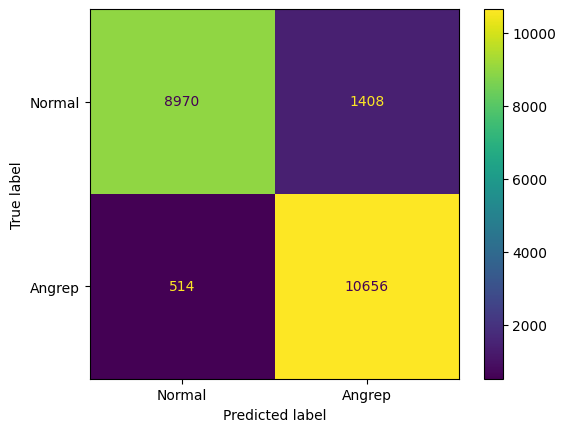

In [ ]:
# Evaluer på valideringssettet

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_val)
print(classification_report(y_val, y_pred, target_names=['Normal', 'Angrep'], digits=3))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred, display_labels=['Normal', 'Angrep'])

#Recall for Angrep: hvor mange av angrepene som ble oppdaget.
#Et oversett angrep er det verste som kan skje for en IDS.

#Precision for Angrep: hvor mange av alarmene som var ekte angrep.

#False positives (normal trafikk merket som angrep, øverst til høyre i confusion matrix):
#for mange gir “alarmtretthet” hos sikkerhetsfolk.

#Macro-F1: et samlet tall som vekter begge klassene likt. Bruk det til å sammenligne modeller.

## Baseline-resultater: Logistic Regression (binær, valideringssett)

**Oppsett:** Logistic Regression (max_iter=1000), preprosessering med one-hot (kategoriske), log1p + StandardScaler (skjeve features) og StandardScaler (øvrige features). Trent på 80 % av det rensede treningssettet, evaluert på 20 % validering (21 548 rader, stratifisert).

| Klasse | Precision | Recall | F1-score | Antall |
|---|---|---|---|---|
| Normal | 0.946 | 0.864 | 0.903 | 10 378 |
| Angrep | 0.883 | 0.954 | 0.917 | 11 170 |
| **Macro avg** | **0.915** | **0.909** | **0.910** | 21 548 |

**Accuracy:** 0.911

**Tolkning:**
- **Recall for angrep er 0.954:** modellen oppdager ca. 95 % av angrepene, så ca. 5 % blir oversett (≈ 514 angrep).
- **Recall for normal er 0.864:** ca. 14 % av normal trafikk blir feilaktig merket som angrep (≈ 1 411 falske alarmer).
- Modellen heller mot å slå alarm. Den fanger de fleste angrepene, men på bekostning av mange false positives. I praksis kan dette gi alarmtretthet hos sikkerhetsanalytikere.
- Etter at duplikatene ble fjernet, er klassene nesten balanserte (ca. 48 % normal og 52 % angrep), så accuracy er her et rimelig mål. Vi bruker likevel **macro-F1 = 0.910** som hovedtall for å sammenligne modeller.

**Dette er baselinen alle senere modeller skal slå.**

=== Logistic Regression ===
              precision    recall  f1-score   support

      Normal      0.946     0.864     0.903     10378
      Angrep      0.883     0.954     0.917     11170

    accuracy                          0.911     21548
   macro avg      0.915     0.909     0.910     21548
weighted avg      0.913     0.911     0.911     21548



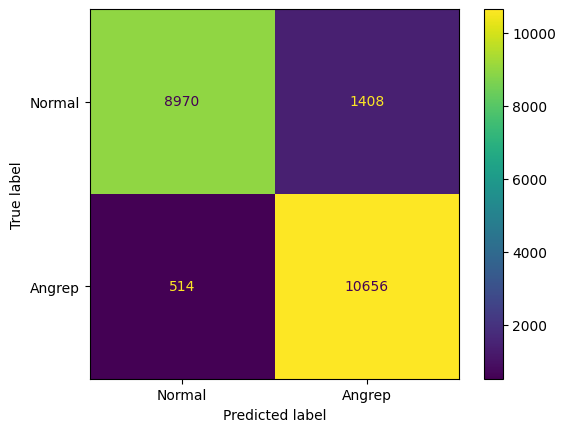

In [ ]:
#Felles evalueringskode

from sklearn.metrics import f1_score

def evaluer(model, X, y, navn):
    y_pred = model.predict(X)
    print(f'=== {navn} ===')
    print(classification_report(y, y_pred, target_names=['Normal', 'Angrep'], digits=3))
    ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Normal', 'Angrep'])
    return f1_score(y, y_pred, average='macro')

resultater = {}
resultater['Logistic Regression'] = evaluer(model, X_val, y_val, 'Logistic Regression')

=== Random Forest ===
              precision    recall  f1-score   support

      Normal      0.944     0.916     0.930     10378
      Angrep      0.924     0.950     0.937     11170

    accuracy                          0.933     21548
   macro avg      0.934     0.933     0.933     21548
weighted avg      0.934     0.933     0.933     21548



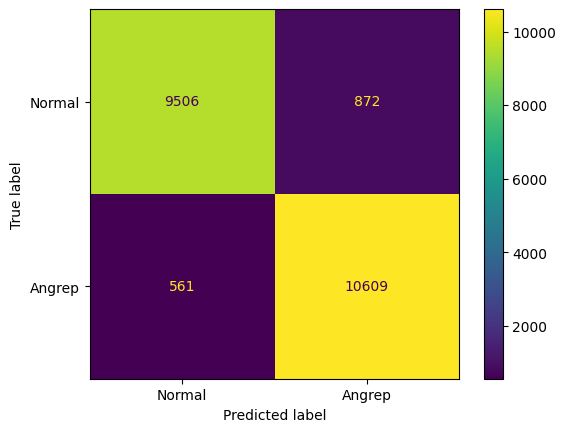

In [ ]:
#Random forest med pipeline

from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ('prep', preprocess),
    ('clf',  RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf.fit(X_tr, y_tr)
resultater['Random Forest'] = evaluer(rf, X_val, y_val, 'Random Forest')

In [ ]:
#Sammenligning

pd.Series(resultater, name='Macro-F1').sort_values(ascending=False)

,Macro-F1
Random Forest,0.933323
Logistic Regression,0.910254
